In [1]:
import numpy as np
import pandas as pd

# Reproducibility
rng = np.random.default_rng(42)

# Experiment design
n_customers = 10_000
baseline_churn_rate = 0.27
treatment_churn_rate = 0.24

# Simulate customer IDs
customer_ids = np.arange(1, n_customers + 1)

# Randomly assign customers to control or treatment
groups = rng.choice(
    ["control", "treatment"],
    size=n_customers,
    p=[0.5, 0.5]
)

# Define the hypothetical churn probability for each group
churn_probabilities = np.where(
    groups == "control",
    baseline_churn_rate,
    treatment_churn_rate
)

# Simulate whether each customer churns: 1 = churn, 0 = retained
churned = rng.binomial(1, churn_probabilities)

# Build the experimental dataset
experiment = pd.DataFrame({
    "customer_id": customer_ids,
    "group": groups,
    "retention_offer": (groups == "treatment").astype(int),
    "churned": churned
})

# Inspect the data
print("Dataset shape:", experiment.shape)
print("\nGroup sizes:")
print(experiment["group"].value_counts())

print("\nObserved churn rates:")
print(experiment.groupby("group")["churned"].agg(
    customers="count",
    churned="sum",
    churn_rate="mean"
))

Dataset shape: (10000, 4)

Group sizes:
group
control      5015
treatment    4985
Name: count, dtype: int64

Observed churn rates:
           customers  churned  churn_rate
group                                    
control         5015     1389    0.276969
treatment       4985     1184    0.237513


In [2]:
from math import sqrt
from statistics import NormalDist

# Summarize the two groups
control = experiment[experiment["group"] == "control"]["churned"]
treatment = experiment[experiment["group"] == "treatment"]["churned"]

n_c, n_t = len(control), len(treatment)
x_c, x_t = int(control.sum()), int(treatment.sum())

p_c = x_c / n_c
p_t = x_t / n_t

# Difference in churn rates: treatment minus control
difference = p_t - p_c

# Relative reduction compared with control
relative_reduction = (p_c - p_t) / p_c

# 95% confidence interval for the difference
# Uses the unpooled standard error (Wald interval)
se_ci = sqrt(
    p_c * (1 - p_c) / n_c
    + p_t * (1 - p_t) / n_t
)

z_critical = NormalDist().inv_cdf(0.975)
ci_lower = difference - z_critical * se_ci
ci_upper = difference + z_critical * se_ci

# Two-sided two-proportion z-test
pooled_rate = (x_c + x_t) / (n_c + n_t)

se_test = sqrt(
    pooled_rate * (1 - pooled_rate)
    * (1 / n_c + 1 / n_t)
)

z_statistic = difference / se_test
p_value = 2 * (1 - NormalDist().cdf(abs(z_statistic)))

# Report results
print(f"Control churn rate:       {p_c:.2%}")
print(f"Treatment churn rate:     {p_t:.2%}")
print(f"Absolute reduction:       {(p_c - p_t):.2%} percentage points")
print(f"Relative reduction:       {relative_reduction:.2%}")
print(f"95% CI for treatment - control: "
      f"[{ci_lower:.2%}, {ci_upper:.2%}]")
print(f"Z-statistic:              {z_statistic:.3f}")
print(f"P-value:                  {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    print("Decision: Reject the null hypothesis at the 5% level.")
else:
    print("Decision: Fail to reject the null hypothesis at the 5% level.")

Control churn rate:       27.70%
Treatment churn rate:     23.75%
Absolute reduction:       3.95% percentage points
Relative reduction:       14.25%
95% CI for treatment - control: [-5.66%, -2.23%]
Z-statistic:              -4.513
P-value:                  0.000006
Decision: Reject the null hypothesis at the 5% level.


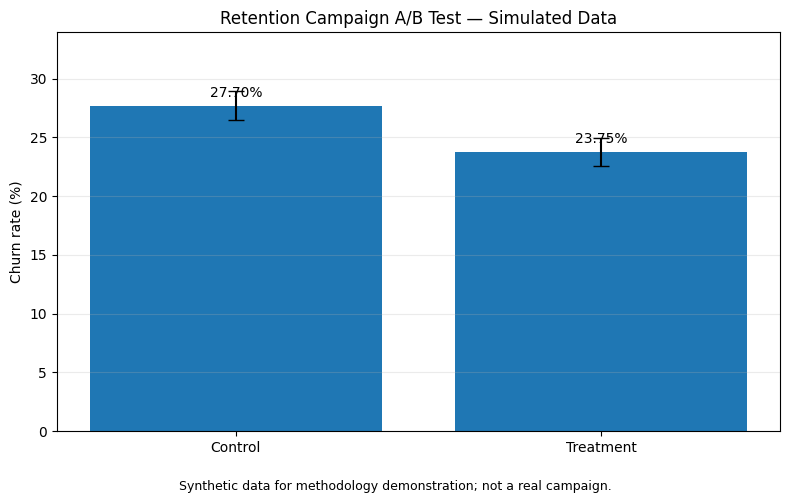

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate approximate 95% confidence intervals for each churn rate
rates = np.array([p_c, p_t])
sample_sizes = np.array([n_c, n_t])

standard_errors = np.sqrt(
    rates * (1 - rates) / sample_sizes
)
errors = 1.96 * standard_errors

labels = ["Control", "Treatment"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    rates * 100,
    yerr=errors * 100,
    capsize=6
)

ax.set_ylabel("Churn rate (%)")
ax.set_title("Retention Campaign A/B Test — Simulated Data")
ax.set_ylim(0, max((rates + errors) * 100) + 5)
ax.grid(axis="y", alpha=0.25)

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.2%}",
        ha="center",
        va="bottom"
    )

fig.text(
    0.5, 0.01,
    "Synthetic data for methodology demonstration; not a real campaign.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

### Results and business interpretation

This project demonstrates a simulated randomized A/B test evaluating whether a hypothetical customer-retention offer reduces churn.

The control group had an observed churn rate of 27.70%, compared with 23.75% in the treatment group. The absolute difference was a 3.95-percentage-point reduction, equivalent to a relative reduction of approximately 14.25%.

A two-proportion z-test returned a z-statistic of −4.513 and a p-value of approximately 0.000006. The 95% confidence interval for the treatment-minus-control difference was approximately −5.66 to −2.23 percentage points. The null hypothesis of equal churn rates was rejected at the 5% significance level.

**Business implications:** If a comparable effect were observed in a real experiment, the reduction could be commercially valuable. However, a deployment decision would require assessing incentive costs, customer lifetime value, implementation costs, and the results of a properly conducted real-world experiment.

**Limitations:** The data and treatment effect are simulated using assumed churn probabilities. Therefore, the results demonstrate an analytical workflow and do not establish the effectiveness of a real retention campaign. The confidence intervals and hypothesis test also rely on assumptions about random assignment and independent customer outcomes.

In [4]:
# Illustrative business assumptions — change these as needed
rollout_customers = 10_000
value_per_retained_customer = 400  # euros of contribution margin
offer_cost_per_customer = 15       # euros
operating_cost_per_customer = 2    # euros

# Estimated churn reduction from the experiment
churn_reduction = p_c - p_t

# Scale the estimated effect to the proposed rollout
expected_retained = rollout_customers * churn_reduction

# Estimated financial impact
expected_benefit = (
    expected_retained * value_per_retained_customer
)

total_campaign_cost = rollout_customers * (
    offer_cost_per_customer + operating_cost_per_customer
)

net_benefit = expected_benefit - total_campaign_cost
roi = net_benefit / total_campaign_cost

# Translate the confidence interval into retained customers
reduction_lower = -ci_upper
reduction_upper = -ci_lower

retained_lower = rollout_customers * reduction_lower
retained_upper = rollout_customers * reduction_upper

net_lower = (
    retained_lower * value_per_retained_customer
    - total_campaign_cost
)
net_upper = (
    retained_upper * value_per_retained_customer
    - total_campaign_cost
)

break_even_value = (
    total_campaign_cost / expected_retained
)

print("ILLUSTRATIVE BUSINESS IMPACT")
print(f"Proposed campaign size: {rollout_customers:,}")
print(f"Expected customers retained: {expected_retained:.0f}")
print(f"Estimated contribution value: €{expected_benefit:,.2f}")
print(f"Total campaign cost: €{total_campaign_cost:,.2f}")
print(f"Estimated net benefit: €{net_benefit:,.2f}")
print(f"Estimated ROI: {roi:.1%}")
print(f"Break-even value per retained customer: €{break_even_value:,.2f}")

print("\nUNCERTAINTY ANALYSIS")
print(
    f"Retained customers based on 95% CI: "
    f"{retained_lower:.0f}–{retained_upper:.0f}"
)
print(
    f"Net benefit based on 95% CI: "
    f"€{net_lower:,.2f} to €{net_upper:,.2f}"
)

ILLUSTRATIVE BUSINESS IMPACT
Proposed campaign size: 10,000
Expected customers retained: 395
Estimated contribution value: €157,826.22
Total campaign cost: €170,000.00
Estimated net benefit: €-12,173.78
Estimated ROI: -7.2%
Break-even value per retained customer: €430.85

UNCERTAINTY ANALYSIS
Retained customers based on 95% CI: 223–566
Net benefit based on 95% CI: €-80,637.18 to €56,289.62
